# ARAI feature engineering and feature exploration

This notebook reads the frozen model features and explanatory evidence of every development world, checks that
they reproduce, and then explores them against private truth. It follows
`final-spec/components/06-feature-engineering.md` (specification v1.4) and was extended after an independent
review (`records/2026-10-02-features-critic-review.md`) with sections 6b and 6c.

**Two strict phases.**
1. *Features* are computed from the seven operational tables only: no label, persona or group membership.
   Identifiers are used for equality alone. The result is frozen under `data/artifacts/features/` by
   `arai.experiment.train` before any model is fitted.
2. *Exploration* joins private truth afterwards, offline, on training worlds only. It can describe a feature,
   but nothing found here is allowed to change a feature without a dated record.

No model is fitted here. The single-feature AUCs below describe the features; they are not model results.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from arai import dataset, feature_eda, features as F
from arai.generator import load_world
from arai.paths import REPO_ROOT
from arai.settings import load_settings

pd.set_option("display.max_columns", 40, "display.width", 220, "display.precision", 3, "display.max_rows", 60)
experiment = load_settings().experiment
FIXTURES = [f"W{s}" for s in experiment["fixture_seeds"]]
TRAINING = [f"W{s}" for s in experiment["train_seeds"]]
STRESS = [f"W{s}" for s in experiment["stress_seeds"]]
REPORT_DIR = REPO_ROOT / "reports" / "features" / "2026-10-02"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

SURFACE, INK, SECONDARY, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, QUIET = "#2a78d6", "#eb6834", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": SECONDARY,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": SECONDARY, "ytick.labelcolor": SECONDARY,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False, "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

## 1. The model features and the evidence-only measures

The contract `final-spec/contracts/features.yaml` fixes the order of the model features, the rows they are
computed on and when they are null. A null is a real state (for example, no return request at all), never a
zero. Two link measures are computed alongside and shown to the analyst, but are never model inputs (decision
AM-26): sharing an identifier is not guilt.

In [2]:
contract = __import__("yaml").safe_load((REPO_ROOT / "final-spec/contracts/features.yaml").read_text())
print(len(contract["ordered_features"]), "model features")
display(pd.DataFrame(contract["ordered_features"])[["name", "definition", "scope", "null"]])
print("evidence only, never a model input:")
display(pd.DataFrame(contract["evidence_only"]["features"])[["name", "definition", "scope", "null"]])

17 model features


,name,definition,scope,null
0,mature_sale_lines,count mature delivered sale lines,mature_sales,0
1,log_order_count,log1p unique orders with >=1 delivered line,all_delivered,0
2,raw_return_rate,requested mature units / purchased mature units,mature_sales,null if denominator zero
3,expected_return_rate,sum(q*p_cs) / mature units,mature_sales,null if denominator zero
4,residual_z,"(R-E)/sqrt(d*V), two-level self-excluded peers",mature_sales,null if V zero
5,claim_share,transaction claim requested units / all reques...,all_visible_nonwithdrawn_requests,null without requests
6,requested_refund_ratio,requested net value / purchased net value on m...,mature_sales,null if net denominator zero
7,damage_reason_share,customer complaint group units / requested units,all_visible_nonwithdrawn_requests,null without requests
8,bracketing_share,mature units in order/style with >=2 distinct ...,mature_sales,null if no mature units
9,late_window_share,request units with capped window ratio >=.75 /...,all_visible_nonwithdrawn_requests,null without valid timing


evidence only, never a model input:


,name,definition,scope,null
0,max_identifier_fanout,max distinct account fanout of own observed ID...,all_visible_orders,0 without orders
1,supported_neighbor_count,unique adjacent accounts with >=2 valid shared...,all_visible_orders,0 empty valid graph


## 2. Frozen training reference, and the frozen features of every development world

One thing is learned from training worlds and then frozen: the category return rates used when a category has
no peers in a snapshot. Everything else is an aggregate of the snapshot being scored and is recomputed, never
learned. The last line recomputes one world from its operational tables and checks that the frozen file is
reproduced exactly.

In [3]:
reference = dataset.reference_from_worlds(TRAINING)
display(pd.DataFrame(reference.to_dict()).round(3))
built = []
for world_id in FIXTURES + TRAINING + STRESS:
    f = dataset.load_features(world_id)
    meta = json.loads((dataset.feature_dir(world_id) / "meta.json").read_text())
    assert meta["feature_order"] == dataset.MODEL_FEATURES and meta["reference"] == reference.to_dict()
    built.append({"world": world_id, "customers": len(f), "eligible": int(f["eligible"].sum()),
                  "graph_edges": len(pd.read_parquet(dataset.feature_dir(world_id) / "edges.parquet")),
                  "category_fallback_uses": meta["fallback_uses"]})
built = pd.DataFrame(built)
display(built)
assert (built["category_fallback_uses"] == 0).all()   # so the features of these worlds do not depend on the reference
tables, manifest = dataset.load_operational(TRAINING[0])
again = F.compute_features(tables, dataset.snapshot_date(manifest), reference).features.assign(world_id=TRAINING[0])
pd.testing.assert_frame_equal(again, dataset.load_features(TRAINING[0]))
print(TRAINING[0], "recomputed from operational tables: identical to the frozen features")

,category_rate
Dress,0.246
Jacket,0.177
Jeans,0.219
Shirt,0.203
T-shirt,0.180


,world,customers,eligible,graph_edges,category_fallback_uses
0,W2001,1000,548,121,0
1,W2002,1000,626,93,0
2,W2003,1000,545,77,0
3,W2101,10000,5682,946,0
4,W2102,10000,5692,991,0
5,W2103,10000,5614,1077,0
6,W2104,10000,5672,1003,0
7,W2105,10000,5599,973,0
8,W2106,10000,5621,975,0
9,W2107,10000,5706,1025,0


W2101 recomputed from operational tables: identical to the frozen features


`category_fallback_uses` is zero everywhere: every category has peers in every world, so no model feature
depends on the frozen reference. That matters later: cross-validation folds can share these feature files
without a held-out world having influenced a training world's features.

## 3. Join private truth (training worlds, offline) and look at the features

In [4]:
frames, wardrobing = [], []
for world_id in TRAINING:
    world = load_world(world_id)
    result = F.compute_features(world.tables, world.snapshot_date, reference)
    frames.append(feature_eda.labelled_frame(world, result))
    wardrobing.append(result.wardrobing.assign(world_id=world_id))
frame = pd.concat(frames, ignore_index=True)
wardrobing = pd.concat(wardrobing, ignore_index=True)
eligible = frame[frame["eligible"]]
print(f"{len(frame):,} customers, {len(eligible):,} eligible, {int(eligible['y_abuse'].sum()):,} eligible abusers")
display(eligible[dataset.MODEL_FEATURES].describe(percentiles=[0.5, 0.95]).T[["count", "mean", "min", "50%", "95%", "max"]])

100,000 customers, 56,615 eligible, 3,181 eligible abusers


,count,mean,min,50%,95%,max
mature_sale_lines,56615.0,20.242,3.000,13.000,56.000,242.000
log_order_count,56615.0,2.349,0.693,2.303,3.664,5.112
raw_return_rate,56615.0,0.192,0.000,0.167,0.500,1.000
expected_return_rate,56615.0,0.200,0.134,0.200,0.227,0.327
residual_z,56615.0,-0.030,-6.081,-0.303,2.961,14.057
claim_share,45876.0,0.112,0.000,0.000,0.667,1.000
requested_refund_ratio,56615.0,0.198,0.000,0.166,0.546,1.000
damage_reason_share,45876.0,0.097,0.000,0.000,0.500,1.000
bracketing_share,56615.0,0.035,0.000,0.000,0.229,1.000
late_window_share,45876.0,0.026,0.000,0.000,0.167,1.000


## 4. Each feature on its own

For every feature, among eligible customers: the AUC where the feature exists (0.5 means no information, below
0.5 means lower values indicate abuse), its range across the ten worlds, how often it is missing for honest
customers and for abusers, and the AUC of the missing-value flag alone.

,auc,auc_min_world,auc_max_world,missing_honest,missing_abuser,auc_of_missing,median_honest,median_abuser
feature,,,,,,,,
requested_refund_ratio,0.800,0.785,0.817,0.000,0.000,NaN,0.156,0.378
raw_return_rate,0.794,0.781,0.809,0.000,0.000,NaN,0.167,0.333
residual_z,0.793,0.778,0.805,0.000,0.000,NaN,-0.393,1.482
claim_share,0.784,0.768,0.811,0.201,0.000,0.400,0.000,0.353
max_identifier_fanout,0.713,0.694,0.733,0.000,0.000,NaN,1.000,3.000
supported_neighbor_count,0.659,0.637,0.686,0.000,0.000,NaN,0.000,0.000
late_return_lines,0.632,0.615,0.649,0.000,0.000,NaN,0.000,0.000
late_window_share,0.623,0.610,0.646,0.201,0.000,0.400,0.000,0.000
occasion_return_share,0.619,0.578,0.646,0.201,0.000,0.400,0.091,0.222


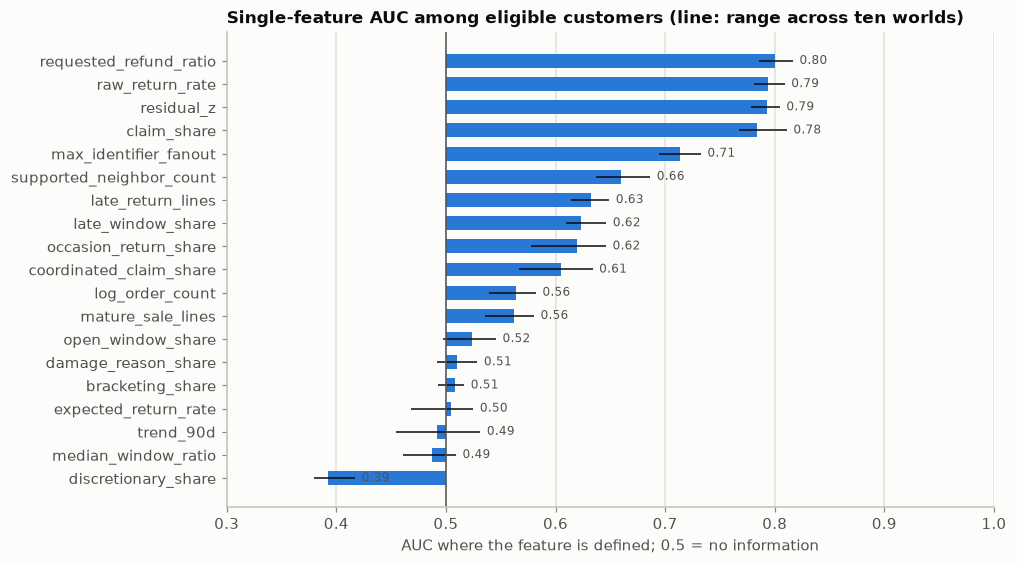

In [5]:
uni = feature_eda.univariate(frame)
display(uni.sort_values("auc", ascending=False))
uni.to_csv(REPORT_DIR / "univariate.csv")

order = uni["auc"].sort_values().index
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(order, uni.loc[order, "auc"] - 0.5, left=0.5, height=0.6, color=BLUE)
ax.hlines(order, uni.loc[order, "auc_min_world"], uni.loc[order, "auc_max_world"], color=INK, linewidth=1)
ax.axvline(0.5, color=SECONDARY, linewidth=1)
for name in order:
    ax.text(max(uni.loc[name, "auc"], uni.loc[name, "auc_max_world"]) + 0.006, name, f"{uni.loc[name, 'auc']:.2f}", va="center", fontsize=8, color=SECONDARY)
ax.set_title("Single-feature AUC among eligible customers (line: range across ten worlds)")
ax.set_xlabel("AUC where the feature is defined; 0.5 = no information")
ax.set_xlim(0.3, 1.0)
ax.grid(axis="y", visible=False)
plt.show()

In [6]:
missing = uni[["missing_honest", "missing_abuser", "auc_of_missing"]].query("missing_honest > 0 or missing_abuser > 0")
display(missing.sort_values("auc_of_missing", ascending=False))

,missing_honest,missing_abuser,auc_of_missing
feature,,,
trend_90d,0.416,0.342,0.463
claim_share,0.201,0.000,0.400
late_window_share,0.201,0.000,0.400
damage_reason_share,0.201,0.000,0.400
median_window_ratio,0.201,0.000,0.400
occasion_return_share,0.201,0.000,0.400
discretionary_share,0.201,0.000,0.400
coordinated_claim_share,0.806,0.251,0.223


The second table is the one to keep in mind for modelling. Where a feature is missing far more often for honest
customers than for abusers, the model can separate the classes from the gap alone: having any return request,
any claim, or any claim with a linked neighbour is itself evidence. That is legitimate behaviour, not a leak,
but it means the missing-value indicators will carry real weight and the explanation shown to an analyst should
say "has claims" rather than only "high claim share".

## 5. Honest customers and abusers on the strongest features

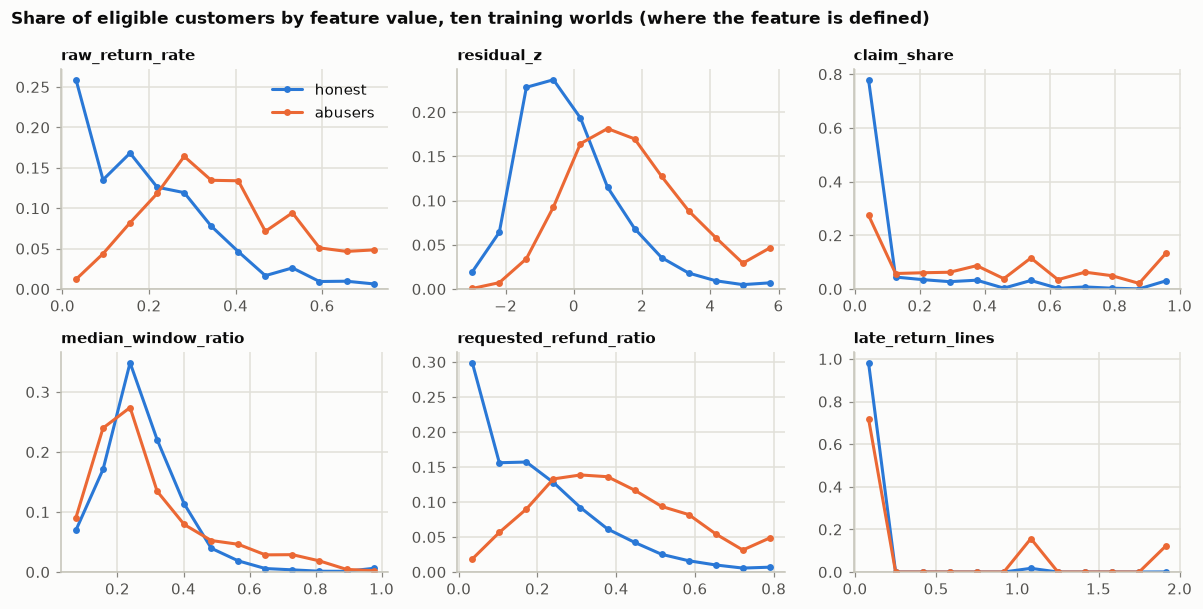

In [7]:
chosen = ["raw_return_rate", "residual_z", "claim_share", "median_window_ratio", "requested_refund_ratio", "late_return_lines"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, name in zip(axes.ravel(), chosen):
    values = eligible[name].dropna()
    lo, hi = values.quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 13) if hi > lo else np.linspace(lo - 0.5, lo + 0.5, 3)
    for label, mask, colour in (("honest", eligible["y_abuse"] == 0, BLUE), ("abusers", eligible["y_abuse"] == 1, ORANGE)):
        part = eligible.loc[mask, name].dropna().clip(lo, hi)
        share = np.histogram(part, bins=bins)[0] / max(len(part), 1)
        ax.plot((bins[:-1] + bins[1:]) / 2, share, color=colour, marker="o", markersize=3.5, label=label)
    ax.set_title(name, fontsize=10)
    ax.set_ylim(bottom=0)
axes[0, 0].legend(loc="upper right")
fig.suptitle("Share of eligible customers by feature value, ten training worlds (where the feature is defined)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

## 6. Which signal belongs to which behaviour

Mean feature values by behaviour group, eligible customers only. Groups are assigned in the order shown, so each
customer is in exactly one: ring claimants first, then other abusers, then the three honest look-alike groups
the gate protects, then everyone else. This table is the backbone of the explanation for a non-specialist: the
return-rate rule reads only the third row.

In [8]:
profile = feature_eda.group_profile(frame)
columns = ["honest: other", "honest: heavy returner", "honest: defective-product buyer", "honest: household",
           "abuser: solo claims", "abuser: ring claims", "abuser: temporary use", "abuser: claims and temporary use"]
display(profile[[c for c in columns if c in profile]].round(3))
profile.to_csv(REPORT_DIR / "group_profile.csv")

group,honest: other,honest: heavy returner,honest: defective-product buyer,honest: household,abuser: solo claims,abuser: ring claims,abuser: temporary use,abuser: claims and temporary use
mature_sale_lines,15.825,16.749,39.355,16.105,23.729,21.320,23.517,32.925
log_order_count,2.189,2.188,3.023,2.227,2.566,2.406,2.547,2.806
raw_return_rate,0.132,0.520,0.215,0.131,0.359,0.412,0.331,0.430
expected_return_rate,0.200,0.203,0.202,0.200,0.200,0.202,0.200,0.201
residual_z,-0.561,2.866,0.096,-0.579,1.698,1.944,1.408,2.807
claim_share,0.098,0.075,0.069,0.111,0.554,0.618,0.047,0.342
requested_refund_ratio,0.136,0.527,0.221,0.134,0.357,0.440,0.386,0.468
damage_reason_share,0.043,0.069,0.287,0.040,0.048,0.042,0.123,0.069
bracketing_share,0.034,0.041,0.035,0.034,0.033,0.029,0.034,0.041
late_window_share,0.021,0.021,0.021,0.019,0.012,0.018,0.235,0.140


## 6b. Which behaviour each feature can see

AUC of each feature for one kind of abuser against all honest eligible customers, with missing values set to the
pooled median as the models do. A value near 0.5 means the feature cannot see that behaviour at all. No single
feature sees every kind of abuse, which is the reason a one-number rule cannot do the job.

In [9]:
by_type = feature_eda.by_abuse_type(frame)
display(by_type.round(3))
by_type.to_csv(REPORT_DIR / "auc_by_abuse_type.csv")

,abuser: claims and temporary use (93),abuser: ring claims (1012),abuser: solo claims (1018),abuser: temporary use (1058)
mature_sale_lines,0.659,0.521,0.579,0.575
log_order_count,0.653,0.522,0.584,0.578
raw_return_rate,0.872,0.836,0.779,0.761
expected_return_rate,0.524,0.525,0.494,0.495
residual_z,0.896,0.831,0.779,0.759
claim_share,0.910,0.951,0.941,0.516
requested_refund_ratio,0.879,0.836,0.757,0.800
damage_reason_share,0.593,0.500,0.512,0.625
bracketing_share,0.551,0.499,0.510,0.510
late_window_share,0.823,0.527,0.518,0.827


## 6c. Honest look-alikes and hard-to-see abusers

Counted before any model exists, so the error account later is not a surprise:

- **ring members with no completed action** are honest by label but linked like a ring;
- **repeat claimants** are honest customers with two or more claim lines, mostly at addresses where deliveries
  genuinely fail; the second table shows how weakly single features separate them from abusers who only claim;
- **one-action abusers** have done one thing, once.

In [10]:
alike = feature_eda.lookalikes(frame)
display(alike["counts"]); display(alike["separation"].round(3))
print("share of eligible abusers with exactly one completed action:", round(alike["one_action_share_of_abusers"], 3))
alike["counts"].to_csv(REPORT_DIR / "lookalikes.csv", index=False)

,group,customers
0,eligible honest customers,53434
1,honest ring members (no completed action yet),298
2,honest with any claim line,10356
3,honest repeat claimants (two or more claim lines),3897
4,eligible abusers,3181
5,abusers with two or more claim lines,1790
6,abusers with exactly one completed action,921
7,abusers with no claim line (temporary use only),800


,measure,auc_solo_claim_abuser_vs_honest_repeat_claimant
0,claim_lines,0.504
1,claim_share,0.655
2,raw_return_rate,0.667
3,residual_z,0.644
4,requested_refund_ratio,0.646
5,mature_sale_lines,0.285


share of eligible abusers with exactly one completed action: 0.29


## 7. How the features relate to each other

,feature_a,feature_b,spearman
0,mature_sale_lines,log_order_count,0.971
1,raw_return_rate,requested_refund_ratio,0.947
2,raw_return_rate,residual_z,0.927
3,residual_z,requested_refund_ratio,0.870
4,max_identifier_fanout,supported_neighbor_count,0.813
5,late_window_share,late_return_lines,0.571
6,coordinated_claim_share,supported_neighbor_count,0.505
7,coordinated_claim_share,max_identifier_fanout,0.416
8,requested_refund_ratio,occasion_return_share,0.315
9,mature_sale_lines,bracketing_share,0.287


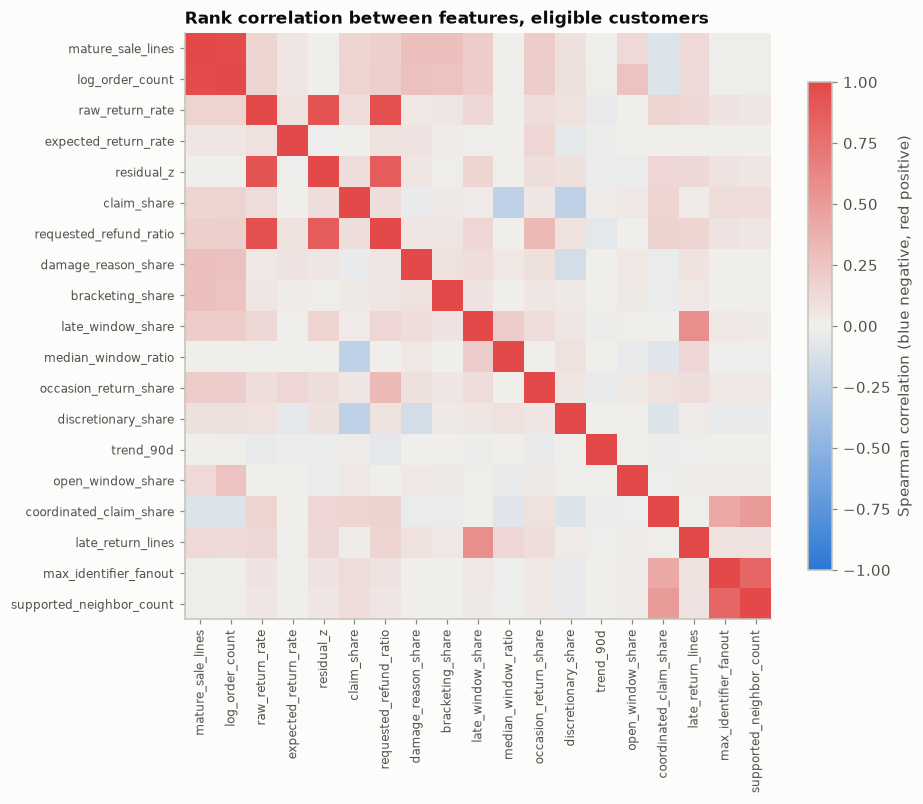

In [11]:
corr = feature_eda.correlations(frame)
display(feature_eda.strongest_pairs(corr))
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(8.6, 7.2))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman correlation (blue negative, red positive)")
ax.set_title("Rank correlation between features, eligible customers")
plt.show()
corr.to_csv(REPORT_DIR / "correlations.csv")

## 8. Volume as a shortcut

Completed abuse is more common among customers with more orders, simply because they had more chances. The two
volume features carry that. This is the check that the model will not be mostly a volume ranking.

In [12]:
volume = uni.loc[["mature_sale_lines", "log_order_count", "open_window_share", "trend_90d"], ["auc", "auc_min_world", "auc_max_world"]]
display(volume)
by_persona = eligible.groupby("persona")[["raw_return_rate", "residual_z", "claim_share", "supported_neighbor_count"]].mean()
by_persona["customers"] = eligible.groupby("persona").size()
by_persona["abusers"] = eligible.groupby("persona")["y_abuse"].sum()
display(by_persona.round(3))

,auc,auc_min_world,auc_max_world
feature,,,
mature_sale_lines,0.562,0.536,0.580
log_order_count,0.564,0.539,0.582
open_window_share,0.524,0.498,0.546
trend_90d,0.492,0.455,0.531


,raw_return_rate,residual_z,claim_share,supported_neighbor_count,customers,abusers
persona,,,,,,
High_Intensity,0.435,3.254,0.056,0.333,1801,193
Loyalist,0.176,-0.364,0.112,0.261,15647,894
New_Growth,0.177,-0.177,0.138,0.341,6291,454
Occasional,0.157,-0.315,0.139,0.336,19193,904
Seasonal,0.236,0.389,0.083,0.287,13683,736


## 9. The wardrobing indicator against actual temporary use

The indicator is independent of the model score. It cannot establish that a garment was worn. It counts *late
returns*: item returns requested in the last quarter of the return window and still inside it. Two or more are
`elevated`; one is `possible` only when it was occasion wear or at least half of the customer's item returns
(decision AM-28, which replaced a rule built on customer-level medians that found one temporary-use customer in
eight).

In [13]:
report = feature_eda.wardrobing_report(frame, wardrobing)
display(report["status_by_truth"]); display(report["bands"].round(3)); display(report["false_alerts"].round(3))
report["bands"].to_csv(REPORT_DIR / "wardrobing_bands.csv", index=False)
report["false_alerts"].to_csv(REPORT_DIR / "wardrobing_false_alerts.csv", index=False)

temporary_use_return,no temporary use,temporary use
status,,
elevated,25,394
insufficient_evidence,12472,0
no_elevated_signal,42622,533
possible,270,299


,band,flagged,true_temporary_use,precision,recall,temporary_use_customers
0,elevated,419,394,0.940,0.321,1226
1,elevated or possible,988,693,0.701,0.565,1226


,honest_group,customers,alerted,alert_rate
0,any late item return,955,289,0.303
1,size bracketers,11171,82,0.007
2,all honest eligible,53434,289,0.005


## 10. Stability across worlds, and a saved summary

In [14]:
per_world = eligible.groupby("world_id")[dataset.MODEL_FEATURES].mean()
spread = pd.DataFrame({"mean": per_world.mean(), "lowest_world": per_world.min(), "highest_world": per_world.max()})
spread["relative_range"] = (spread["highest_world"] - spread["lowest_world"]) / spread["mean"].abs().replace(0, np.nan)
display(spread.round(3))
summary = {"date": "2026-10-02", "specification": "1.4", "training_worlds": TRAINING, "model_features": dataset.MODEL_FEATURES,
           "customers": int(len(frame)), "eligible": int(len(eligible)), "eligible_abusers": int(eligible["y_abuse"].sum()),
           "category_fallback_uses": int(built["category_fallback_uses"].sum()),
           "univariate_auc": uni["auc"].round(4).to_dict(), "auc_of_missing": uni["auc_of_missing"].dropna().round(4).to_dict(),
           "wardrobing": report["bands"].to_dict(orient="records"),
           "wardrobing_false_alerts": report["false_alerts"].to_dict(orient="records"),
           "auc_by_abuse_type": by_type.round(4).to_dict(), "lookalikes": alike["counts"].to_dict(orient="records"),
           "one_action_share_of_abusers": alike["one_action_share_of_abusers"]}
(REPORT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=float) + "\n", encoding="utf-8")
print("reports written to", REPORT_DIR.relative_to(REPO_ROOT))

,mean,lowest_world,highest_world,relative_range
mature_sale_lines,20.241,19.968,20.624,0.032
log_order_count,2.349,2.332,2.363,0.013
raw_return_rate,0.192,0.188,0.197,0.046
expected_return_rate,0.200,0.196,0.205,0.042
residual_z,-0.030,-0.041,-0.019,0.717
claim_share,0.112,0.105,0.114,0.081
requested_refund_ratio,0.198,0.192,0.203,0.055
damage_reason_share,0.097,0.095,0.101,0.059
bracketing_share,0.035,0.033,0.036,0.109
late_window_share,0.026,0.023,0.028,0.183


reports written to reports\features\2026-10-02


## Limits

- Single-feature AUCs describe features one at a time on simulated data. They are not model performance, and
  they are measured on the same worlds the generator was explored on.
- The features were designed with knowledge of how the generator works, so strong separation here says the
  features recover the simulation, not that they would work on real returns.
- Findings and any decision they lead to are recorded in `records/2026-10-02-features.md`.